# Proyecto 2: Regresión Lineal Múltiple

**Carrera:** Tecnicatura Universitaria en Tecnologías de Programación

**Materia:** Programación Python Avanzada

**Integrantes:** Olivera Yohana y Urriola Itziar

**Dataset:** Software Developer Salary Prediction 

**Fuente:** Kaggle.com

**Link Dataset:** https://www.kaggle.com/datasets/nudratabbas/software-developer-salary-prediction-dataset

**Link Repositorio GitHub:** https://github.com/Itz-U/Proyecto2_Olivera_Urriola_UPSO-Salliquelo.git

### Descripción del dataset

El dataset, contiene información sobre los salarios de desarrolladores de software y distintas características de su perfil profesional.

Está compuesto por 50.000 registros y 7 variables, distribuidos originalmente en dos archivos: train.csv con 40.000 registros y test.csv con 10.000 registros.

Entre las variables se encuentran los años de experiencia profesional, el país de residencia, el nivel educativo, los lenguajes de programación, los frameworks utilizados y el tamaño de la empresa. Además, incluye el salario expresado en dólares estadounidenses (salary_usd), que será nuestra variable objetivo.

### Justificación de la elección

Se eligió este dataset ya que se vincula con el campo de la programación, área correspondiente a nuestra formación profesional, y permite analizar cómo distintas características profesionales pueden influir en los salarios de los desarrolladores de software.

Asimismo, cuenta con una cantidad considerable de registros y variables que pueden utilizarse para desarrollar un Modelo de Regresión Lineal Múltiple implementando Python. Resulta de interés investigar qué factores presentan una mayor relación con el salario y en qué medida es posible estimarlo a partir de ellos.

### Objetivo de predicción

El objetivo es desarrollar un modelo de regresión lineal múltiple que permita predecir el salario de un desarrollador de software en dólares, utilizando variables relacionadas con su experiencia laboral, formación académica y características profesionales.

A partir del modelo, buscamos evaluar la precisión de las predicciones, identificar las variables con mayor influencia sobre el salario y comparar los resultados obtenidos con los datos de entrenamiento y test.

### Diccionario de variables

| Columna | Tipo de Dato | Descripción |
|--------|--------------|-------------|
| experience| int64 | Años de experiencia profesional en programación. |
| country | str | País de residencia del desarrollador. |
| education | str | Nivel más alto de educación formal alcanzado. |
| languages | str | Principales lenguajes de programación utilizados. |
| frameworks | str | Principales frameworks utilizados. |
| company_size | str | Cantidad de empleados de la empresa. |
| salary_usd | int64 | Variable objetivo: salario en dólares estadounidenses que se busca predecir. |

## Parte 1: Análisis exploratorio de datos

### **Importación de librerías y exploración inicial**


Se importaron las librerías necesarias para trabajar con los datos, realizar cálculos y generar visualizaciones.

El dataset original está dividido en dos archivos: train.csv y test.csv. Para este proyecto, se decidió unificar ambos archivos en un único DataFrame con el fin de trabajar con la totalidad de los registros disponibles y, posteriormente, realizar una división aleatoria propia entre entrenamiento y prueba. Esta decisión se adoptó para evitar posibles sesgos asociados a una partición predefinida de los datos y para que el desempeño del modelo no dependa de una división ajena al estudio. De este modo, se busca que la evaluación del modelo sea más objetiva y representativa, no artificialmente favorable, sino que refleje de manera más realista su capacidad de predicción.

In [246]:
# Importamos las librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance


# Cargamos los archivos del dataset
df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

# Unificamos ambos archivos
df_original = pd.concat([df_train, df_test], ignore_index=True)

# Generamos una copia para trabajar sin alterar el original
df = df_original.copy()

Transformamos los nombres de las columnas al español, para facilitar el uso y el análisis

In [247]:
df = df.rename(columns={
    "experience": "experiencia",
    "country": "pais",
    "education": "educacion",
    "languages": "lenguajes",
    "company_size": "tamano_empresa",
    "salary_usd": "salario_usd"
})

print(df.columns.tolist())
df.head()

['experiencia', 'pais', 'educacion', 'lenguajes', 'frameworks', 'tamano_empresa', 'salario_usd']


,experiencia,pais,educacion,lenguajes,frameworks,tamano_empresa,salario_usd
0,34,Germany,Masters,"Rust, JavaScript","Vue, ASP.NET",201-1000,172292
1,9,UK,Masters,"C#, JavaScript","Ruby on Rails, Spring",201-1000,82311
2,8,USA,Some College,"C++, Go","Vue, React",5000+,109637
3,29,USA,Masters,"C++, Ruby","Spring, Angular",11-50,214386
4,7,USA,Bachelors,"C#, Rust","React, Express",1-10,107584


Utilizamos **`.shape[ ]`** para conocer las dimensiones del dataset, es decir cuantas filas y columnas tiene.

In [248]:
print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas")

Dimensiones del dataset: 50000 filas y 7 columnas


Con el método **`.info( )`** obtenemos el nombre de las columnas, un conteo de valores NO nulos y el tipo de dato que contiene cada columna.

In [249]:
print("Información general y tipos de datos:")
df.info()

Información general y tipos de datos:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   experiencia     50000 non-null  int64
 1   pais            50000 non-null  str  
 2   educacion       50000 non-null  str  
 3   lenguajes       50000 non-null  str  
 4   frameworks      50000 non-null  str  
 5   tamano_empresa  50000 non-null  str  
 6   salario_usd     50000 non-null  int64
dtypes: int64(2), str(5)
memory usage: 2.7 MB


En la información anterior notamos que:

* El dataset no presenta datos nulos

Utilizamos **`.duplicated().sum()`** para comprobar si existen registros completamente duplicados en el dataset unificado.

In [250]:
print("Registros duplicados:", df.duplicated().sum())

Registros duplicados: 0


**Conclusión sobre la calidad de datos:**

* Como muestra la exploración inicial el dataset es robusto ya que cuenta con un total de 50.000 registros. 
* Los tipos de datos son coherentes con la información que representan en la mayoría de las columnas, aunque variables como "lenguajes" y "frameworks", presentan muliples valores y la variable "tamano_empresa" esta expresada en rangos, lo cual nos indica que deberemos tomar decisiones al momento de su utilización en la siguiente etapa
* A nivel de completitud, consideramos que tiene una alta calidad, no se detectaron valores nulos, y posterior a la unificación de los dataset, no se registraron valores duplicados.

### **Análisis de variables** 

#### Variables Categóricas y Numéricas a analizar

Para desarrollar nuestro modelo de regresión lineal múltiple, analizaremos las variables disponibles en el dataset y su posible relación con el salario de los desarrolladores de software.

**Variables numéricas:**

* experiencia: Años de experiencia profesional del desarrollador.
* salario_usd: Salario expresado en dólares estadounidenses. Es nuestra variable objetivo (Y).

**Variables categóricas:**

* pais: País de residencia del desarrollador.
* educacion: Nivel educativo alcanzado.
* lenguajes: Lenguajes de programación utilizados.
* frameworks: Frameworks utilizados.
* tamano_empresa: Tamaño de la empresa donde trabaja.

Analizaremos sus distribuciones y relaciones para comprender mejor los datos e identificar qué características podrían resultar útiles para predecir el salario.

#### Estadísticas descriptivas

Utilizamos el método **`describe()`** para obtener un resumen estadístico de las variables numéricas, incluyendo la media, desviación estándar, valores mínimos y máximos, mediana y cuartiles.

Esto nos permitirá comprender la distribución de los años de experiencia y los salarios de los desarrolladores.

In [251]:
print("Estadísticas dscriptivas de variables numéricas:")
df.describe()

Estadísticas dscriptivas de variables numéricas:


,experiencia,salario_usd
count,50000.000000,50000.000000
mean,19.884320,131689.690060
std,11.868243,46451.633373
min,0.000000,12024.000000
25%,10.000000,98032.750000
50%,20.000000,130396.000000
75%,30.000000,164357.250000
max,40.000000,280900.000000


**Interpretación:**

Los desarrolladores presentan un promedio de **19,88 años de experiencia**, con valores comprendidos entre 0 y 40 años. La mediana es de 20 años, lo que indica que la mitad de los registros corresponde a desarrolladores con 20 años de experiencia o menos.

En cuanto al salario, encontramos un promedio de **131.689,69 USD** y una mediana de **130.396 USD**. Ambos valores son relativamente cercanos, aunque existe una dispersión considerable, reflejada en una desviación estándar de 46.451,63 USD.

Los salarios varían entre 12.024 y 280.900 USD, por lo que resulta interesante analizar su distribución y relación con las características profesionales de los desarrolladores.

#### Distribución de las variables numéricas

**Distribución de la experiencia profesional**

Utilizamos un histograma para visualizar cómo se distribuyen los años de experiencia entre los desarrolladores. Además, incorporamos líneas que representan la media y la mediana para facilitar su interpretación.

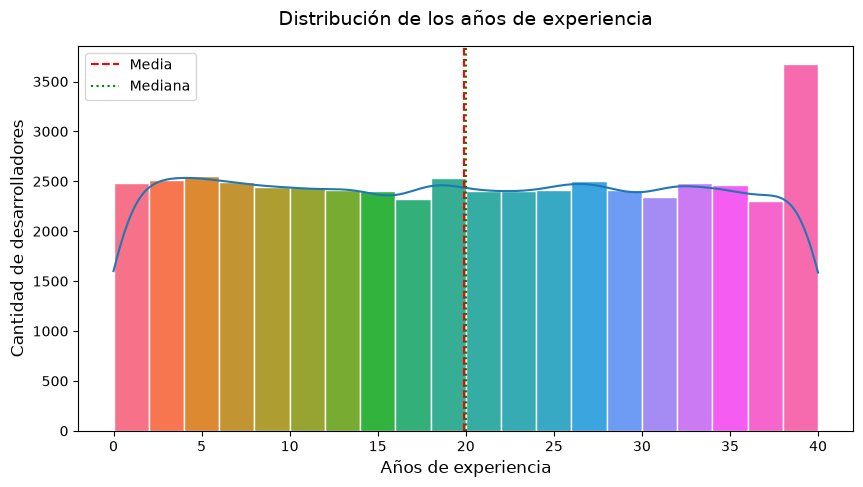

In [252]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    data=df,
    x="experiencia",
    bins=20,
    kde=True,
    edgecolor="white",
    linewidth=1,
    ax=ax
)

# Aplicamos la paleta HUSL
paleta_hist = sns.color_palette("husl", len(ax.patches))

for i, barra in enumerate(ax.patches):
    barra.set_facecolor(paleta_hist[i % len(paleta_hist)])

# Media y mediana
plt.axvline(df["experiencia"].mean(), color="red",
            linestyle="--", label="Media")

plt.axvline(df["experiencia"].median(), color="green",
            linestyle=":", label="Mediana")

plt.title("Distribución de los años de experiencia", fontsize=14, pad=15)
plt.xlabel("Años de experiencia", fontsize=12)
plt.ylabel("Cantidad de desarrolladores", fontsize=12)
plt.legend()
plt.show()

**Distribución de los salarios**

Utilizamos un histograma para analizar la frecuencia de los distintos niveles salariales. Incluimos la media y la mediana para identificar dónde se concentran los valores y observar posibles asimetrías en su distribución.

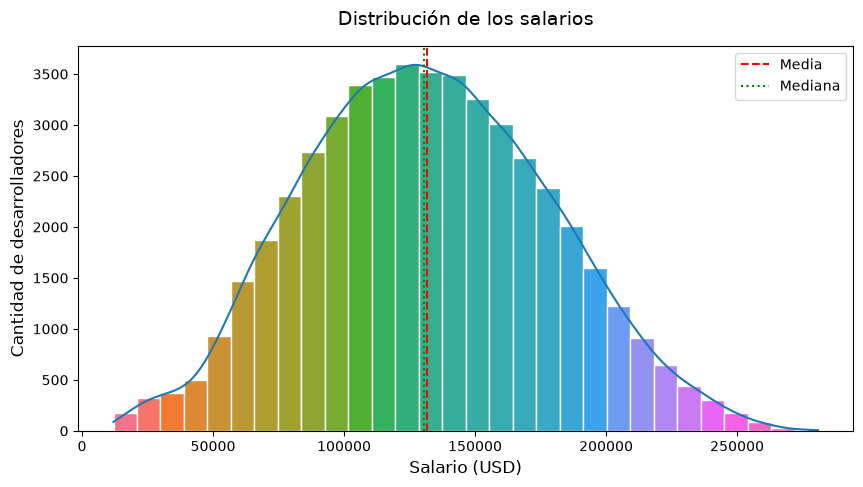

In [253]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    data=df,
    x="salario_usd",
    bins=30,
    kde=True,
    edgecolor="white",
    linewidth=1,
    ax=ax
)

# Aplicamos la paleta HUSL
paleta_hist = sns.color_palette("husl", len(ax.patches))

for i, barra in enumerate(ax.patches):
    barra.set_facecolor(paleta_hist[i % len(paleta_hist)])

# Media y mediana
plt.axvline(df["salario_usd"].mean(), color="red",
            linestyle="--", label="Media")

plt.axvline(df["salario_usd"].median(), color="green",
            linestyle=":", label="Mediana")

plt.title("Distribución de los salarios", fontsize=14, pad=15)
plt.xlabel("Salario (USD)", fontsize=12)
plt.ylabel("Cantidad de desarrolladores", fontsize=12)
plt.legend()
plt.show()

#### Análisis de las variables categóricas

**Exploración de variables categóricas**

Utilizamos nunique() para identificar la cantidad de valores distintos que presenta cada variable categórica. Esto nos permitirá conocer su diversidad y evaluar posteriormente qué tratamiento necesitarán para incorporarlas al modelo.

In [254]:
# Cantidad de valores únicos por variable categórica
categoricas = [
    "pais", "educacion", "lenguajes",
    "frameworks", "tamano_empresa"
]

df[categoricas].nunique()

pais               10
educacion           5
lenguajes         100
frameworks        100
tamano_empresa      6
dtype: int64

**Distribución de las variables categóricas**

Mediante gráficos de barras analizamos la cantidad de desarrolladores registrados según su país de residencia, nivel educativo y tamaño de empresa.

Esto nos permitirá identificar qué categorías tienen mayor representación dentro del dataset.

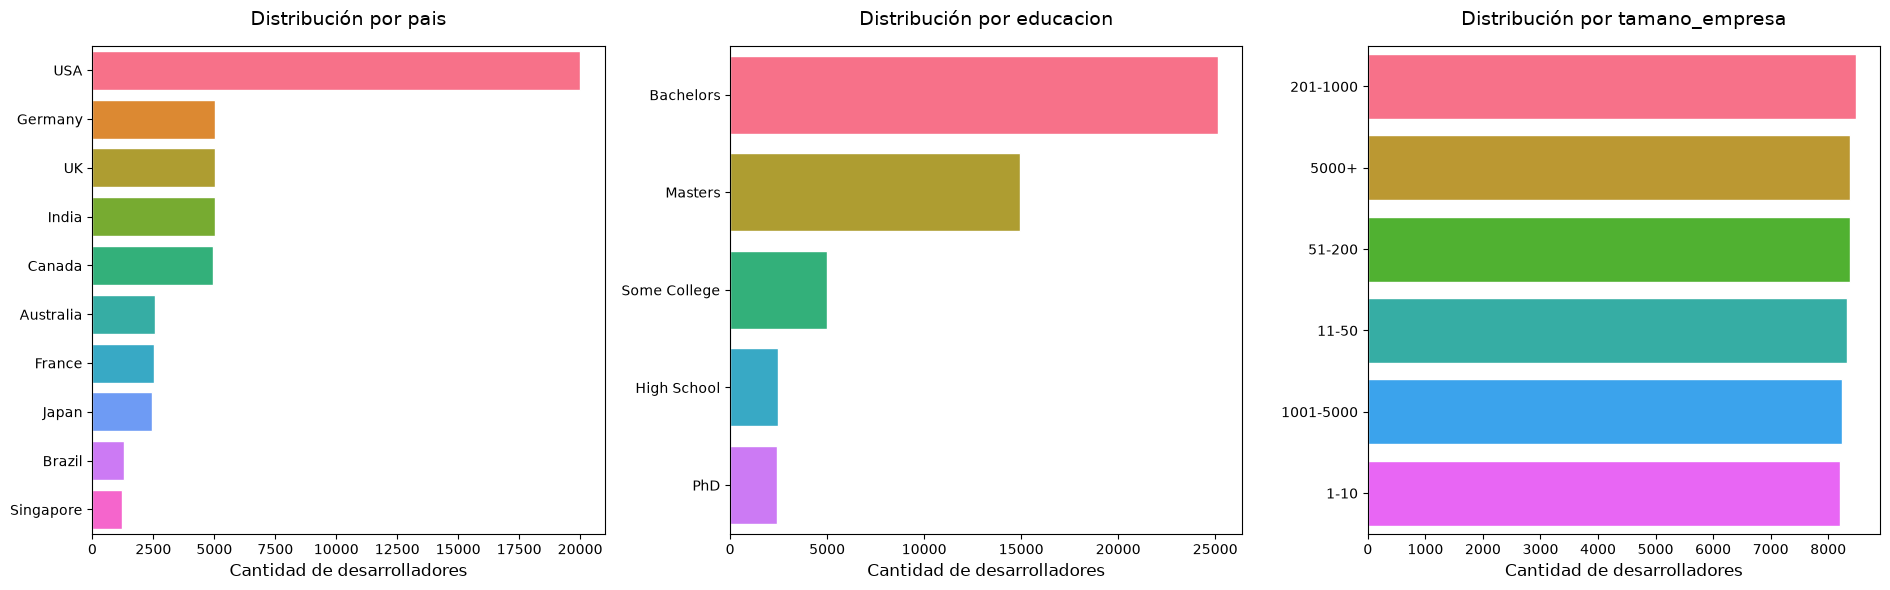

In [255]:
# Variables categóricas a visualizar
variables = ["pais", "educacion", "tamano_empresa"]

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

for ax, variable in zip(axes, variables):

    frecuencias = df[variable].value_counts()

    sns.barplot(
        x=frecuencias.values,
        y=frecuencias.index,
        color="steelblue",
        edgecolor="white",
        linewidth=1,
        ax=ax
    )

    # Paleta HUSL
    paleta_barras = sns.color_palette("husl", len(ax.patches))

    for i, barra in enumerate(ax.patches):
        barra.set_facecolor(paleta_barras[i])

    ax.set_title(f"Distribución por {variable}", fontsize=14, pad=15)
    ax.set_xlabel("Cantidad de desarrolladores", fontsize=12)
    ax.set_ylabel("")

plt.tight_layout()
plt.show()


**Relación entre experiencia profesional y salario**

Utilizamos un gráfico de dispersión (scatter plot) para analizar la relación entre los años de experiencia y el salario de los desarrolladores.

Cada punto representa un registro del dataset. El objetivo es observar si existe una tendencia creciente o decreciente y si la relación entre ambas variables presenta un comportamiento aproximadamente lineal.

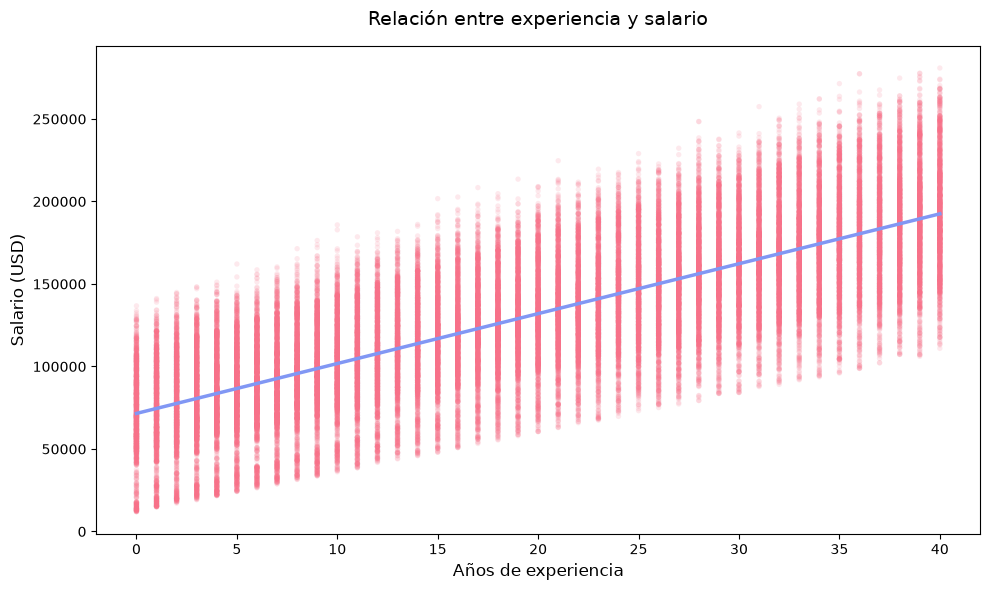

In [256]:
fig, ax = plt.subplots(figsize=(10, 6))

# Paleta HUSL
color_puntos = sns.color_palette("husl", 7)[0]
color_linea = sns.color_palette("husl", 7)[5]

sns.regplot(
    data=df,
    x="experiencia",
    y="salario_usd",
    scatter_kws={
        "alpha": 0.15,
        "s": 15,
        "color": color_puntos,
        "edgecolors": "none"
    },
    line_kws={
        "color": color_linea,
        "linewidth": 2.5
    },
    ci=None,
    ax=ax
)

plt.title("Relación entre experiencia y salario", fontsize=14, pad=15)
plt.xlabel("Años de experiencia", fontsize=12)
plt.ylabel("Salario (USD)", fontsize=12)

plt.tight_layout()
plt.show()

**Coeficiente de correlación de Pearson**

Calculamos el coeficiente de correlación entre experiencia y salario

In [257]:
# Correlación entre experiencia y salario
correlacion = df["experiencia"].corr(df["salario_usd"])

print(f"Correlación de Pearson: {correlacion:.4f}")


Correlación de Pearson: 0.7727


**Interpretación:**

El coeficiente de correlación de Pearson obtenido es de **0,7727**, lo que indica una relación lineal positiva relativamente fuerte entre los años de experiencia y el salario.

Esto significa que, dentro del dataset, los desarrolladores con mayor experiencia tienden a presentar salarios más elevados.

Este resultado sugiere que la experiencia profesional podría ser una variable predictora importante para nuestro modelo de regresión lineal múltiple. Sin embargo, la correlación no implica causalidad ni garantiza por sí sola una buena predicción.

#### Matriz de correlación

Utilizamos una matriz de correlación para visualizar la intensidad y dirección de las relaciones lineales entre las variables numéricas del dataset.

Por el momento, analizamos únicamente `experiencia` y `salario_usd`, ya que las variables categóricas todavía no han sido transformadas.

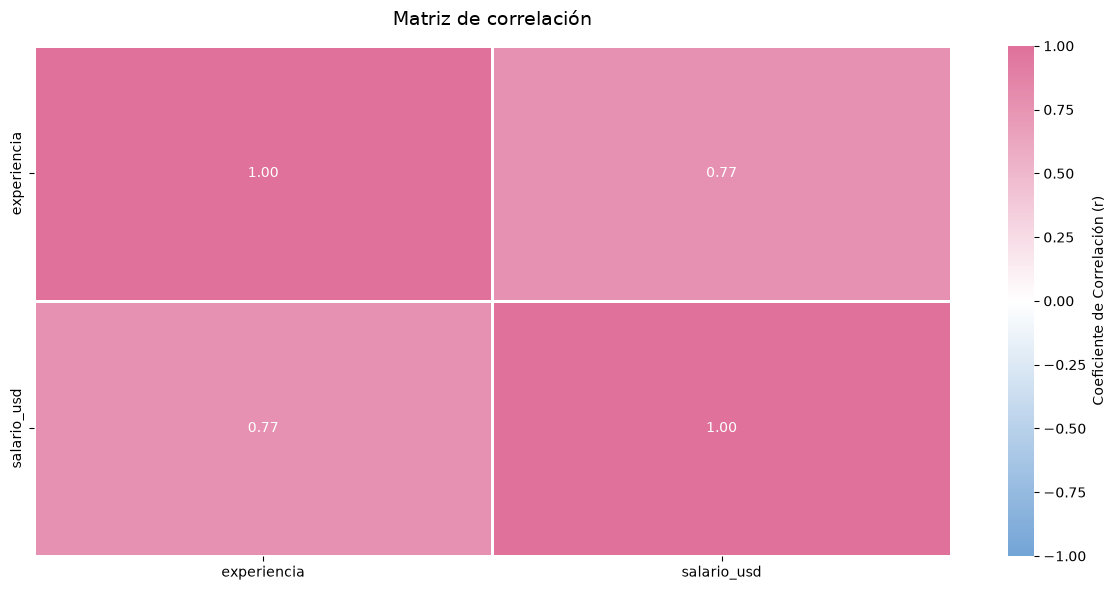

In [258]:
# Importamos la clase LinearSegmentedColormap para crear un mapa de colores personalizado
from matplotlib.colors import LinearSegmentedColormap

plt.figure(figsize=(12, 6))

# Seleccionamos las variables numéricas
numericas = df[["experiencia", "salario_usd"]]

# Calculamos la matriz de correlación
matriz_corr = numericas.corr()

# Definimos paleta de colores
color_negativo = '#73A4D6'  
color_neutro = '#FFFFFF'    
color_positivo = '#DF719A'  

# Creamos una variable para la paleta de colores 
mi_gradiente = LinearSegmentedColormap.from_list('custom_cmap', [color_negativo, color_neutro, color_positivo])

# Generamos el Heatmap
sns.heatmap(
    matriz_corr, 
    annot=True, 
    fmt='.2f', 
    cmap=mi_gradiente, 
    vmin=-1, 
    vmax=1, 
    linewidths=0.8,
    cbar_kws={'label': 'Coeficiente de Correlación (r)'}
)

plt.title("Matriz de correlación", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

#### Relación entre lenguajes de programación y salario

Consideramos interesante analizar si existen diferencias salariales entre los desarrolladores según los lenguajes de programación que utilizan.

Debido a que la columna lenguajes contiene múltiples tecnologías por registro, separaremos los lenguajes para analizarlos individualmente.

Posteriormente, calcularemos el salario promedio y la mediana correspondientes a cada lenguaje, con el objetivo de identificar posibles diferencias salariales y evaluar su utilidad como variables predictoras.

In [259]:

# Separamos los lenguajes y eliminamos repeticiones
df["lista_lenguajes"] = df["lenguajes"].apply(
    lambda texto: list(dict.fromkeys(
        lenguaje.strip() for lenguaje in texto.split(",")
    ))
)

# Creamos una tabla para analizar cada lenguaje
df_lenguajes = df[["lista_lenguajes", "salario_usd"]].explode(
    "lista_lenguajes"
)

df_lenguajes.head()


,lista_lenguajes,salario_usd
0,Rust,172292
0,JavaScript,172292
1,C#,82311
1,JavaScript,82311
2,C++,109637


In [260]:

# Calculamos estadísticas salariales por lenguaje
salarios_lenguajes = (
    df_lenguajes.groupby("lista_lenguajes")["salario_usd"]
    .agg(["count", "mean", "median"])
    .sort_values(by="mean", ascending=False)
    .round(2)
)

# Renombramos las columnas
salarios_lenguajes.columns = [
    "Desarrolladores",
    "Salario promedio",
    "Salario mediano"
]

display(salarios_lenguajes)


,Desarrolladores,Salario promedio,Salario mediano
lista_lenguajes,,,
Rust,9475,132481.62,130485.0
Swift,9520,131993.25,130826.5
Go,9472,131957.55,130399.0
C#,9395,131923.27,131049.0
Python,9669,131750.88,131194.0
Java,9485,131641.51,130214.0
Ruby,9515,131452.69,129942.0
PHP,9434,131399.85,130216.0
C++,9540,130857.40,129489.0


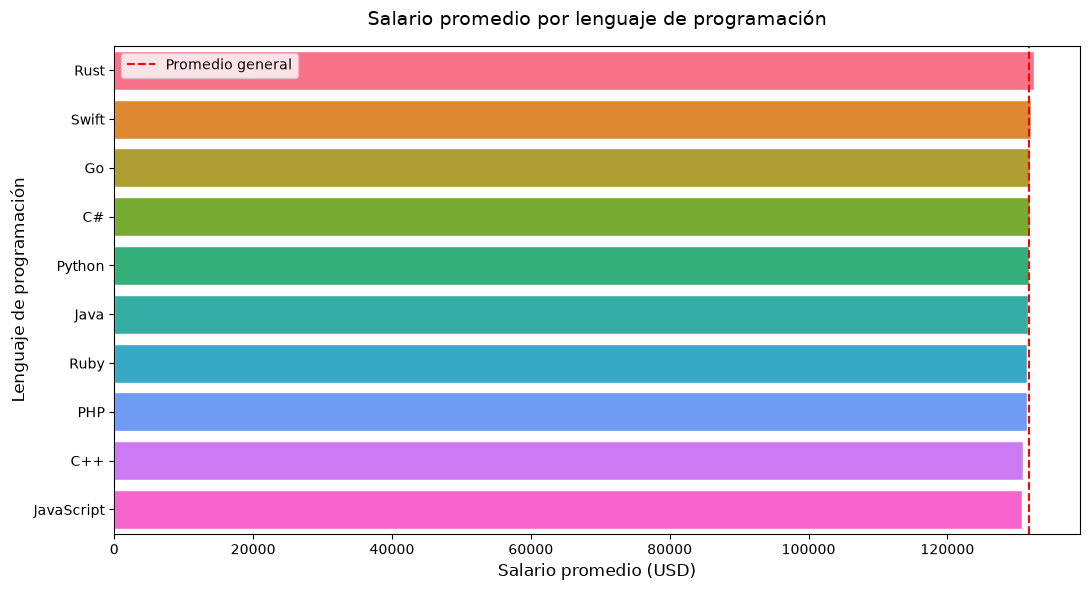

In [261]:

fig, ax = plt.subplots(figsize=(11, 6))

# Ordenamos los salarios de mayor a menor
datos_grafico = salarios_lenguajes.sort_values(
    by="Salario promedio", ascending=False
)

sns.barplot(
    data=datos_grafico,
    x="Salario promedio",
    y=datos_grafico.index,
    color="steelblue",
    edgecolor="white",
    linewidth=1,
    errorbar=None,
    ax=ax
)

# Aplicamos la paleta HUSL
paleta_barras = sns.color_palette("husl", len(ax.patches))

for i, barra in enumerate(ax.patches):
    barra.set_facecolor(paleta_barras[i])

# Línea del salario promedio general
ax.axvline(
    df["salario_usd"].mean(),
    color="red",
    linestyle="--",
    label="Promedio general"
)

plt.title("Salario promedio por lenguaje de programación",
          fontsize=14, pad=15)
plt.xlabel("Salario promedio (USD)", fontsize=12)
plt.ylabel("Lenguaje de programación", fontsize=12)
plt.xlim(left=0)
plt.legend()
plt.tight_layout()
plt.show()


**Interpretación:**

Al comparar los salarios promedio según los lenguajes de programación, observamos que **Rust presenta el promedio más elevado (132.481,60 USD)**, seguido por Swift y Go. Por otro lado, JavaScript presenta el promedio más bajo (130.787,80 USD).

Sin embargo, las diferencias entre los salarios promedio son relativamente pequeñas, por lo que no se observa una relación especialmente marcada entre el lenguaje de programación utilizado y el nivel salarial. Esto sugiere que los lenguajes podrían aportar información adicional al modelo, aunque probablemente sea necesario combinarlos con otras características, como la experiencia profesional, el país y el nivel educativo. Además, los resultados representan asociaciones descriptivas y no permiten afirmar que utilizar un lenguaje determinado provoque un aumento o disminución del salario.

**Conclusión del análisis de variables**


El análisis exploratorio permitió conocer las características principales del dataset e identificar posibles relaciones entre las variables profesionales y el salario de los desarrolladores de software.

Observamos una **correlación positiva relativamente fuerte entre la experiencia profesional y el salario (r = 0,77)**, lo que sugiere que los desarrolladores con mayor experiencia tienden a recibir salarios más elevados.

También analizamos la relación entre los lenguajes de programación y el salario promedio. Encontramos que **Rust presenta el salario promedio más alto (132.481,62 USD)** y JavaScript el más bajo (130.787,77 USD). Sin embargo, las diferencias entre los lenguajes son pequeñas, lo que sugiere que el lenguaje utilizado, por sí solo, podría tener una capacidad predictiva limitada.

Estos resultados indican que la experiencia profesional podría ser una variable importante para nuestro modelo, mientras que los lenguajes de programación podrían aportar información complementaria.

Por este motivo, consideramos necesario incorporar otras características, como el país, el nivel educativo, los frameworks utilizados y el tamaño de la empresa, para evaluar si mejoran la capacidad de predicción del modelo de regresión lineal múltiple.

### **Limpieza y preparación de datos**

#### Verificación de la calidad de los datos

Antes de entrenar el modelo de regresión lineal múltiple, verificamos que los datos se encuentren en condiciones adecuadas para su utilización.
Este paso se realizo en la primera sección del presente informe. En el cual, se observó que el dataset no presenta valores nulos ni registros completamente duplicados, por lo que no es necesario eliminar registros ni aplicar métodos de imputación.

Podemos conservar los 50.000 registros disponibles para continuar con la preparación de las variables.

#### Revisión de categorías

Analizamos los valores que contienen las variables categóricas para identificar cómo están representadas y determinar qué transformaciones serán necesarias antes de utilizarlas en el modelo.

En particular, revisaremos las variables pais, educacion y tamano_empresa, además de los lenguajes de programación y frameworks utilizados.

In [262]:
for columna in ["pais", "educacion", "tamano_empresa"]:
    print(f"\nCategorías de {columna}:")
    print(df[columna].value_counts())



Categorías de pais:
pais
USA          20002
Germany       5032
UK            5010
India         5007
Canada        4938
Australia     2570
France        2533
Japan         2434
Brazil        1281
Singapore     1193
Name: count, dtype: int64

Categorías de educacion:
educacion
Bachelors       25138
Masters         14963
Some College     4995
High School      2469
PhD              2435
Name: count, dtype: int64

Categorías de tamano_empresa:
tamano_empresa
201-1000     8476
5000+        8382
51-200       8379
11-50        8322
1001-5000    8239
1-10         8202
Name: count, dtype: int64


**Interpretación**

Las variables categóricas presentan una cantidad limitada de categorías, lo que facilita su transformación a una representación numérica.

Para incorporarlas al modelo de regresión lineal múltiple, utilizaremos una codificación que permita representar cada categoría sin asignarles un orden numérico artificial.

#### Preparación de frameworks

Al igual que los lenguajes de programación, la variable frameworks contiene múltiples tecnologías dentro de una misma celda, separadas por comas. Para preparar la información, se separó los frameworks en listas individuales, eliminando posibles repeticiones dentro de cada registro. Esto permitirá analizar las tecnologías de manera independiente y preparar su posterior codificación numérica.

In [263]:
# Separamos los frameworks
df["lista_frameworks"] = df["frameworks"].apply(
    lambda texto: list(dict.fromkeys(
        framework.strip() for framework in texto.split(",")
    ))
)

# Visualizamos las tecnologías separadas
df[["lista_lenguajes", "lista_frameworks"]].head()


,lista_lenguajes,lista_frameworks
0,"[Rust, JavaScript]","[Vue, ASP.NET]"
1,"[C#, JavaScript]","[Ruby on Rails, Spring]"
2,"[C++, Go]","[Vue, React]"
3,"[C++, Ruby]","[Spring, Angular]"
4,"[C#, Rust]","[React, Express]"


#### Análisis de frecuencia de frameworks

Se analizó la frecuencia de los diferentes frameworks registrados en el dataset. Para ello, se contabilizó  cada framework individualmente y se representó los resultados mediante un gráfico de barras, con el objetivo de identificar cuáles son los más utilizados por los desarrolladores.

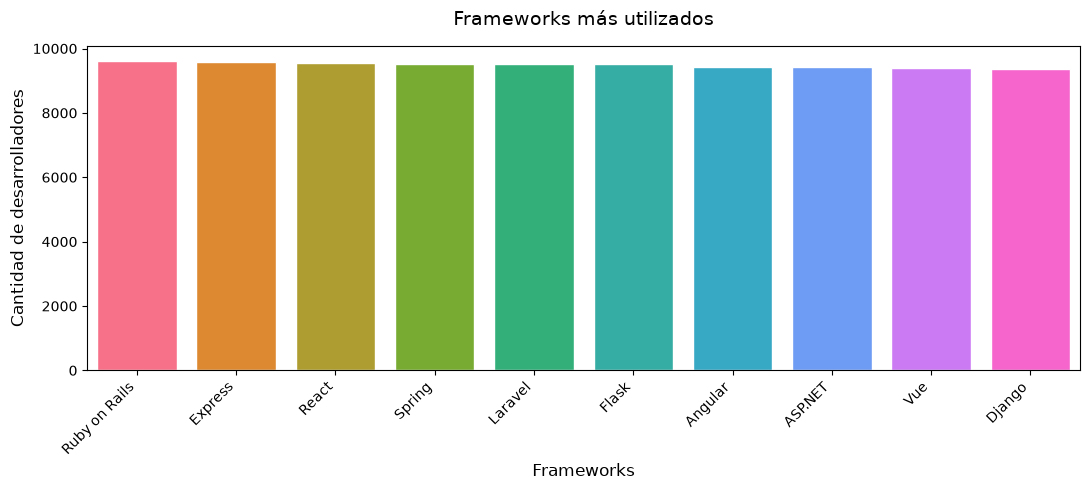

In [264]:
# Contamos la frecuencia de cada framework
frecuencia_frameworks = (
    df["lista_frameworks"]
    .explode()
    .value_counts()
)

fig, ax = plt.subplots(figsize=(11, 5))

sns.barplot(
    x=frecuencia_frameworks.index,
    y=frecuencia_frameworks.values,
    color="steelblue",
    edgecolor="white",
    linewidth=1,
    ax=ax
)

# Paleta HUSL
paleta_barras = sns.color_palette("husl", len(ax.patches))

for i, barra in enumerate(ax.patches):
    barra.set_facecolor(paleta_barras[i])

plt.title("Frameworks más utilizados", fontsize=14, pad=15)
plt.xlabel("Frameworks", fontsize=12)
plt.ylabel("Cantidad de desarrolladores", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


**Interpretación**

El gráfico permitió identificar los frameworks con mayor presencia en el dataset y comparar su frecuencia de utilización entre los desarrolladores. Como cada registro puede contener más de un framework, una persona puede contabilizarse en varias categorías.

Este análisis nos permitió conocer la distribución de las tecnologías utilizadas, aunque su frecuencia no indica necesariamente que estén relacionadas con salarios más elevados.

#### Codificación de variables categóricas

Para poder utilizar las variables categóricas en el modelo de regresión lineal múltiple, se decidió transformar las mismas a variables numéricas. Para ello se utilizará One-Hot Encoding en las variables pais, educacion y tamano_empresa. En el caso de lenguajes y frameworks, se decidió utilizar una codificación binaria por tecnología. La variable experiencia conservará su representación numérica original, mientras que salario_usd será la variable objetivo.

Estas transformaciones se aplicarán después de dividir el dataset en entrenamiento y test, para evitar que la información del conjunto de prueba intervenga en el ajuste del procesamiento.

**Conclusión de la limpieza y preparación de datos**

* El dataset presenta una estructura adecuada para continuar con el desarrollo del modelo, ya que no contiene valores nulos ni registros duplicados.

* Se identificó que las variables relacionadas con el país, nivel educativo y tamaño de empresa son categóricas, mientras que las columnas de lenguajes y frameworks contienen múltiples tecnologías por registro. Para facilitar su análisis, se separó los lenguajes de programación y frameworks en listas individuales, evitando repeticiones dentro de cada registro.

* Finalmente, se definió que las variables categóricas serán transformadas mediante codificación binaria, permitiendo incorporarlas junto con la experiencia profesional al modelo de regresión lineal múltiple.

* La codificación definitiva se realizará después de separar los datos en entrenamiento y test, para garantizar una evaluación adecuada del modelo.

## Parte 2: Regresión lineal múltiple

### **Partición de datos y transformación a estructura matricial**

#### Separación de variables predictoras y objetivo

Para desarrollar el modelo de regresión lineal múltiple, se realizó la separación de las variables predictoras (X) de la variable objetivo (Y).

Las variables predictoras corresponden a las características profesionales de los desarrolladores, mientras que **la variable objetivo es salario_usd**, que representa el salario que se busca estimar.

Como variables de entrada del modelo se utilizaron la experiencia, país, nivel educativo, lenguajes de programación, frameworks y el tamaño de empresa.

In [265]:
# Seleccionamos las variables predictoras
X = df[[
    "experiencia",
    "pais",
    "educacion",
    "tamano_empresa",
    "lista_lenguajes",
    "lista_frameworks"
]]

# Seleccionamos la variable objetivo
y = df["salario_usd"]

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)


Dimensiones de X: (50000, 6)
Dimensiones de y: (50000,)


#### División de los datos en entrenamiento y test

Se utilizó la función train_test_split() de Scikit-learn para dividir aleatoriamente el dataset en dos conjuntos:
- 80 % para entrenamiento: se utilizará para ajustar el modelo de regresión lineal múltiple.
- 20 % para test: se reservará para evaluar su capacidad de predicción con datos que no fueron utilizados durante el entrenamiento.
Se estableció random_state=42 para garantizar que la división sea reproducible y obtener los mismos resultados al ejecutar nuevamente el notebook.

In [266]:
# Dividimos los datos aleatoriamente (80 % - 20 %)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Registros de entrenamiento:", X_train.shape[0])
print("Registros de test:", X_test.shape[0])


Registros de entrenamiento: 40000
Registros de test: 10000


**Interpretación**

El dataset fue dividido aleatoriamente en **40.000 registros para entrenamiento y 10.000 para test**, utilizando una proporción del 80 % y 20 %, respectivamente. Esta separación nos permitirá entrenar el modelo con una parte de los datos y posteriormente evaluar su desempeño con registros diferentes, verificando su capacidad para realizar predicciones sobre datos no utilizados en el entrenamiento.

#### Codificación de variables categóricas

Las variables `pais`, `educacion` y `tamano_empresa` contienen categorías expresadas como texto, por lo que deben transformarse a valores numéricos para utilizarlas en el modelo.

Aplicamos la técnica **One-Hot Encoding**, que crea columnas binarias para representar las diferentes categorías.

Utilizamos `pd.get_dummies()` y eliminamos una categoría de referencia por variable para evitar redundancias en el modelo de regresión lineal.

La codificación se define utilizando las categorías presentes en el conjunto de entrenamiento, manteniendo la misma estructura de columnas para el conjunto de test.

In [267]:
# Variables categóricas que codificaremos
columnas_categoricas = ["pais", "educacion", "tamano_empresa"]

# Codificamos las categorías
cat_train = pd.get_dummies(
    X_train[columnas_categoricas],
    dtype=int
)

cat_test = pd.get_dummies(
    X_test[columnas_categoricas],
    dtype=int
)

# Igualamos las columnas de test con las de entrenamiento
cat_test = cat_test.reindex(
    columns=cat_train.columns,
    fill_value=0
)

# Eliminamos una categoría de referencia por variable
columnas_referencia = []

for columna in columnas_categoricas:
    categorias = sorted(X_train[columna].unique())
    columnas_referencia.append(f"{columna}_{categorias[0]}")

cat_train = cat_train.drop(columns=columnas_referencia)
cat_test = cat_test.drop(columns=columnas_referencia)

# Visualizamos los resultados
cat_train.head()


,pais_Brazil,pais_Canada,pais_France,pais_Germany,pais_India,pais_Japan,pais_Singapore,pais_UK,pais_USA,educacion_High School,educacion_Masters,educacion_PhD,educacion_Some College,tamano_empresa_1001-5000,tamano_empresa_11-50,tamano_empresa_201-1000,tamano_empresa_5000+,tamano_empresa_51-200
39087,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0
30893,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0
45278,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0
16398,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0
13653,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0


#### Codificación de lenguajes y frameworks

Las variables de lenguajes de programación y frameworks contienen múltiples tecnologías por desarrollador.
Para convertirlas a valores numéricos utilizamos MultiLabelBinarizer, que genera una columna binaria por tecnología.

El valor 1 indica que el desarrollador utiliza esa tecnología y el valor 0 que no la utiliza.

Los codificadores se ajustan únicamente con los datos de entrenamiento y luego se aplican al conjunto de test, para evitar utilizar información de prueba durante la preparación del modelo.

In [268]:
# Creamos los codificadores
mlb_lenguajes = MultiLabelBinarizer()
mlb_frameworks = MultiLabelBinarizer()

# Codificamos los lenguajes
leng_train = pd.DataFrame(
    mlb_lenguajes.fit_transform(X_train["lista_lenguajes"]),
    columns=["lenguaje_" + c for c in mlb_lenguajes.classes_],
    index=X_train.index
)

leng_test = pd.DataFrame(
    mlb_lenguajes.transform(X_test["lista_lenguajes"]),
    columns=leng_train.columns,
    index=X_test.index
)

# Codificamos los frameworks
frame_train = pd.DataFrame(
    mlb_frameworks.fit_transform(X_train["lista_frameworks"]),
    columns=["framework_" + c for c in mlb_frameworks.classes_],
    index=X_train.index
)

frame_test = pd.DataFrame(
    mlb_frameworks.transform(X_test["lista_frameworks"]),
    columns=frame_train.columns,
    index=X_test.index
)

# Visualizamos los lenguajes codificados
leng_train.head()


,lenguaje_C#,lenguaje_C++,lenguaje_Go,lenguaje_Java,lenguaje_JavaScript,lenguaje_PHP,lenguaje_Python,lenguaje_Ruby,lenguaje_Rust,lenguaje_Swift
39087,0,0,0,0,0,1,0,0,0,1
30893,0,0,0,1,1,0,0,0,0,0
45278,0,0,0,1,1,0,0,0,0,0
16398,1,0,0,0,0,0,0,0,1,0
13653,0,0,1,0,0,0,1,0,0,0


#### Construcción de las matrices de datos

Una vez transformadas las variables categóricas, unificamos las columnas numéricas y binarias para construir las matrices que utilizaremos en el modelo.

De esta manera, obtenemos dos conjuntos de variables predictoras completamente numéricos, con la misma cantidad y orden de columnas.

Conservamos la variable `experiencia` y agregamos las columnas codificadas correspondientes a país, educación, tamaño de empresa, lenguajes y frameworks.

In [269]:
# Unificamos todas las variables predictoras
X_train_modelo = pd.concat([
    X_train[["experiencia"]],
    cat_train,
    leng_train,
    frame_train
], axis=1)

X_test_modelo = pd.concat([
    X_test[["experiencia"]],
    cat_test,
    leng_test,
    frame_test
], axis=1)

# Verificamos las dimensiones
print("Matriz de entrenamiento:", X_train_modelo.shape)
print("Matriz de test:", X_test_modelo.shape)

# Visualizamos los primeros registros
X_train_modelo.head()


Matriz de entrenamiento: (40000, 39)
Matriz de test: (10000, 39)


,experiencia,pais_Brazil,pais_Canada,pais_France,pais_Germany,pais_India,pais_Japan,pais_Singapore,pais_UK,pais_USA,...,framework_ASP.NET,framework_Angular,framework_Django,framework_Express,framework_Flask,framework_Laravel,framework_React,framework_Ruby on Rails,framework_Spring,framework_Vue
39087,26,0,0,0,0,1,0,0,0,0,...,0,0,0,0,1,0,1,0,0,0
30893,7,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
45278,27,0,0,0,0,0,0,0,0,1,...,0,0,1,0,0,0,0,0,0,0
16398,40,0,1,0,0,0,0,0,0,0,...,0,0,1,1,0,0,0,0,0,0
13653,25,0,0,0,0,1,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0


#### Verificación de los datos preparados

Finalmente, verificamos que las matrices de entrenamiento y test tengan una estructura compatible con el modelo de regresión lineal múltiple. Comprobamos que ambas contengan las mismas variables predictoras, que sus valores sean numéricos y que no existan valores nulos. Esto permite asegurar que los datos estén preparados para la etapa de entrenamiento.

In [270]:
# Comprobamos que las columnas coincidan
print("Mismas columnas:",
      X_train_modelo.columns.equals(X_test_modelo.columns))

# Comprobamos que todos los datos sean numéricos
print("Datos numéricos:",
      all(pd.api.types.is_numeric_dtype(tipo)
          for tipo in X_train_modelo.dtypes))

# Verificamos valores nulos
print("Nulos en entrenamiento:",
      X_train_modelo.isnull().sum().sum())

print("Nulos en test:",
      X_test_modelo.isnull().sum().sum())

# Verificamos la cantidad de variables predictoras
print("Cantidad de variables:", X_train_modelo.shape[1])


Mismas columnas: True
Datos numéricos: True
Nulos en entrenamiento: 0
Nulos en test: 0
Cantidad de variables: 39


**Conclusión de la partición y transformación de datos**

Dividimos aleatoriamente el dataset en **40.000 registros de entrenamiento (80 %) y 10.000 registros de test (20 %)**, utilizando `random_state=42` para garantizar la reproducibilidad del procedimiento.

Posteriormente, transformamos las variables categóricas mediante técnicas de codificación binaria, permitiendo representar numéricamente el país, nivel educativo, tamaño de empresa, lenguajes de programación y frameworks utilizados.

Como resultado, obtuvimos matrices de entrenamiento y test con las mismas variables predictoras, conservando la experiencia profesional como variable numérica original.

Estas transformaciones permitirán utilizar las diferentes características profesionales en el modelo de regresión lineal múltiple. Además, mantuvimos separado el conjunto de test durante el ajuste de los codificadores, con el objetivo de evitar la fuga de información.

De esta manera, los datos quedaron preparados para la siguiente etapa: **el entrenamiento del modelo de regresión lineal múltiple**.

### **Entrenamiento del modelo**

#### Modelo de referencia

Para evaluar posteriormente la utilidad del modelo, comenzamos creando un modelo de referencia mediante DummyRegressor.

Utilizamos la estrategia mean, que consiste en predecir siempre el salario promedio de los registros de entrenamiento, sin considerar las características profesionales de los desarrolladores. Este modelo nos permitirá establecer un punto de comparación para determinar si la regresión lineal múltiple logra mejorar las predicciones.

In [271]:
# Creamos el modelo de referencia
modelo_dummy = DummyRegressor(strategy="mean")

# Entrenamos con los datos de entrenamiento
modelo_dummy.fit(X_train_modelo, y_train)

print("Modelo de referencia entrenado correctamente")
print(f"Salario promedio: {modelo_dummy.constant_[0, 0]:,.2f} USD")


Modelo de referencia entrenado correctamente
Salario promedio: 131,764.52 USD


#### Modelo de regresión lineal múltiple

Utilizamos `LinearRegression` de Scikit-learn para entrenar un modelo de regresión lineal múltiple que permita estimar el salario de los desarrolladores a partir de sus características profesionales. El modelo considera simultáneamente la experiencia laboral, el país de residencia, el nivel educativo, el tamaño de la empresa, los lenguajes de programación y los frameworks utilizados.

Durante el entrenamiento, el algoritmo calcula los coeficientes que permiten ajustar una relación lineal entre las variables predictoras y el salario, buscando minimizar la suma de los errores cuadráticos.

In [272]:
# Creamos el modelo de regresión lineal múltiple
modelo_lineal = LinearRegression()

# Entrenamos utilizando únicamente los datos de entrenamiento
modelo_lineal.fit(X_train_modelo, y_train)

print("Modelo de regresión lineal múltiple entrenado correctamente")


Modelo de regresión lineal múltiple entrenado correctamente


#### Verificación del modelo entrenado

Una vez finalizado el entrenamiento, comprobamos que el modelo haya calculado un intercepto y un coeficiente para cada variable predictora. Estos valores representan los parámetros de la ecuación de regresión lineal múltiple y serán analizados posteriormente para identificar las variables con mayor influencia en las predicciones.

In [273]:
# Consultamos el intercepto
print(f"Intercepto: {modelo_lineal.intercept_:,.2f}")

# Consultamos la cantidad de coeficientes
print("Cantidad de coeficientes:", len(modelo_lineal.coef_))

# Verificamos la cantidad de variables predictoras
print("Variables predictoras:", X_train_modelo.shape[1])


Intercepto: 49,222.58
Cantidad de coeficientes: 39
Variables predictoras: 39


**Conclusión del entrenamiento**

En esta etapa construimos y entrenamos dos modelos utilizando los datos de entrenamiento.
El primero corresponde a un modelo de referencia (`DummyRegressor`), que utiliza el salario promedio como predicción constante.

El segundo corresponde al modelo de regresión lineal múltiple (`LinearRegression`), que utiliza simultáneamente las características profesionales de los desarrolladores para estimar su salario.

Ambos modelos fueron entrenados sin utilizar los registros reservados para test, lo que permitirá realizar una evaluación posterior con datos no utilizados durante el entrenamiento.

En la siguiente sección compararemos el desempeño de ambos modelos utilizando métricas de regresión, con el objetivo de determinar si las variables seleccionadas permiten mejorar la precisión de las predicciones.

### **Evaluación de los modelos**

#### Métricas de evaluación

Para evaluar el desempeño del modelo de regresión lineal múltiple utilizamos tres métricas:
- MAE (Error Absoluto Medio): mide la diferencia absoluta promedio entre los salarios reales y los predichos.
- RMSE (Raíz del Error Cuadrático Medio): mide el error de predicción, dando mayor importancia a las diferencias más grandes.
- R² (Coeficiente de determinación): permite evaluar qué tan bien el modelo explica la variabilidad de los salarios en comparación con una predicción basada en el promedio.
Calcularemos estas métricas tanto para los datos de entrenamiento como para los datos de test. Además, compararemos los resultados de LinearRegression con los obtenidos mediante DummyRegressor.

#### Generación de predicciones 

Utilizamos el método predict() para obtener las estimaciones salariales de los modelos previamente entrenados.

Realizaremos predicciones sobre los datos de entrenamiento y test, permitiendo comparar su comportamiento con registros conocidos y con aquellos que no participaron en el entrenamiento.

In [274]:
# Predicciones del modelo DummyRegressor
y_train_dummy = modelo_dummy.predict(X_train_modelo)
y_test_dummy = modelo_dummy.predict(X_test_modelo)

# Predicciones del modelo de regresión lineal múltiple
y_train_pred = modelo_lineal.predict(X_train_modelo)
y_test_pred = modelo_lineal.predict(X_test_modelo)

print("Predicciones generadas correctamente")


Predicciones generadas correctamente


#### Evaluación con datos de entrenamiento

Evaluamos los modelos utilizando los datos con los que fueron entrenados.

Calculamos MAE, RMSE y R² para conocer el nivel de ajuste de cada modelo y determinar si la regresión lineal múltiple logra reducir los errores en comparación con el modelo de referencia.

In [275]:
# Función para calcular métricas de regresión
def calcular_metricas(y_real, y_predicho):
    mae = mean_absolute_error(y_real, y_predicho)
    rmse = mean_squared_error(y_real, y_predicho) ** 0.5
    r2 = r2_score(y_real, y_predicho)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    }

# Evaluación del modelo de referencia
metricas_dummy_train = calcular_metricas(
    y_train, y_train_dummy
)

# Evaluación de la regresión múltiple
metricas_lineal_train = calcular_metricas(
    y_train, y_train_pred
)

# Tabla comparativa de entrenamiento
tabla_train = pd.DataFrame({
    "DummyRegressor": metricas_dummy_train,
    "LinearRegression": metricas_lineal_train
}).T

display(tabla_train.round(3))


,MAE,RMSE,R²
DummyRegressor,37839.506,46421.897,0.000
LinearRegression,13146.065,15996.208,0.881


**Interpretación de los resultados de entrenamiento:**

Al evaluar los modelos con los datos de entrenamiento, observamos que **LinearRegression presenta un desempeño considerablemente superior al modelo de referencia DummyRegressor**.

El modelo de regresión lineal múltiple obtuvo un **MAE de 13.146,07 USD**, mientras que DummyRegressor presentó un error de 37.839,51 USD. Esto representa una reducción aproximada del 65 % en el error absoluto medio. Asimismo, el RMSE disminuyó de 46.421,90 USD a 15.996,21 USD, lo que indica una reducción importante de los errores de predicción.

Por otra parte, **LinearRegression alcanzó un R² de 0,881**, lo que significa que explica aproximadamente el 88,1 % de la variabilidad de los salarios en el conjunto de entrenamiento. Estos resultados indican que las características profesionales utilizadas aportan información relevante para estimar los salarios y que nuestro modelo logra un ajuste considerablemente mejor que la predicción basada únicamente en el salario promedio. Sin embargo, todavía es necesario evaluar el modelo con los datos de test para comprobar si mantiene su capacidad predictiva frente a registros no utilizados durante el entrenamiento.

#### Evaluación con datos de test

Evaluamos los modelos utilizando el conjunto de test, compuesto por registros que no participaron en el entrenamiento.

Calculamos las mismas métricas de evaluación para determinar si el modelo conserva su capacidad predictiva frente a datos nuevos.

También comparamos los resultados obtenidos por `DummyRegressor` y `LinearRegression`, con el objetivo de comprobar si las características profesionales permiten mejorar las predicciones salariales.

In [276]:

# Evaluación del modelo de referencia
metricas_dummy_test = calcular_metricas(
    y_test, y_test_dummy
)

# Evaluación de la regresión múltiple
metricas_lineal_test = calcular_metricas(
    y_test, y_test_pred
)

# Tabla comparativa de test
tabla_test = pd.DataFrame({
    "DummyRegressor": metricas_dummy_test,
    "LinearRegression": metricas_lineal_test
}).T

display(tabla_test.round(3))


,MAE,RMSE,R²
DummyRegressor,37819.286,46568.375,-0.000
LinearRegression,13185.824,16001.487,0.882


**Interpretación de los resultados de test:**

Al evaluar los modelos con los datos de test, observamos que **LinearRegression presenta un desempeño considerablemente superior al modelo de referencia DummyRegressor**.

El modelo de regresión lineal múltiple obtuvo un **MAE de 13.185,82 USD**, mientras que DummyRegressor presentó un error de **37.819,29 USD**, lo que representa una reducción aproximada del 65 % en el error absoluto medio.

Asimismo, el **RMSE disminuyó de 46.568,38 USD a 16.001,49 USD**, indicando que el modelo lineal también logra reducir considerablemente los errores de mayor magnitud.

Por otra parte, **LinearRegression alcanzó un R² de 0,882**, lo que significa que explica aproximadamente el **88,2 % de la variabilidad de los salarios** en el conjunto de test. En cambio, DummyRegressor obtuvo un R² prácticamente igual a cero.

Estos resultados demuestran que el modelo de regresión lineal múltiple logra realizar predicciones más precisas que el modelo de referencia, utilizando información sobre las características profesionales de los desarrolladores.

Esto sugiere que las variables seleccionadas son buenas predictoras del salario dentro del dataset analizado.

#### Comparación entre entrenamiento y test

Comparamos los resultados de los modelos en ambos conjuntos de datos para analizar su capacidad de generalización.

Una diferencia considerable entre las métricas de entrenamiento y test podría indicar que el modelo presenta dificultades para predecir datos nuevos. También verificamos si la regresión lineal múltiple supera el desempeño del modelo de referencia.

In [277]:

# Construimos una tabla comparativa
resultados = pd.DataFrame({
    "Dummy - Train": metricas_dummy_train,
    "Dummy - Test": metricas_dummy_test,
    "Lineal - Train": metricas_lineal_train,
    "Lineal - Test": metricas_lineal_test
}).T

display(resultados.round(3))


,MAE,RMSE,R²
Dummy - Train,37839.506,46421.897,0.000
Dummy - Test,37819.286,46568.375,-0.000
Lineal - Train,13146.065,15996.208,0.881
Lineal - Test,13185.824,16001.487,0.882


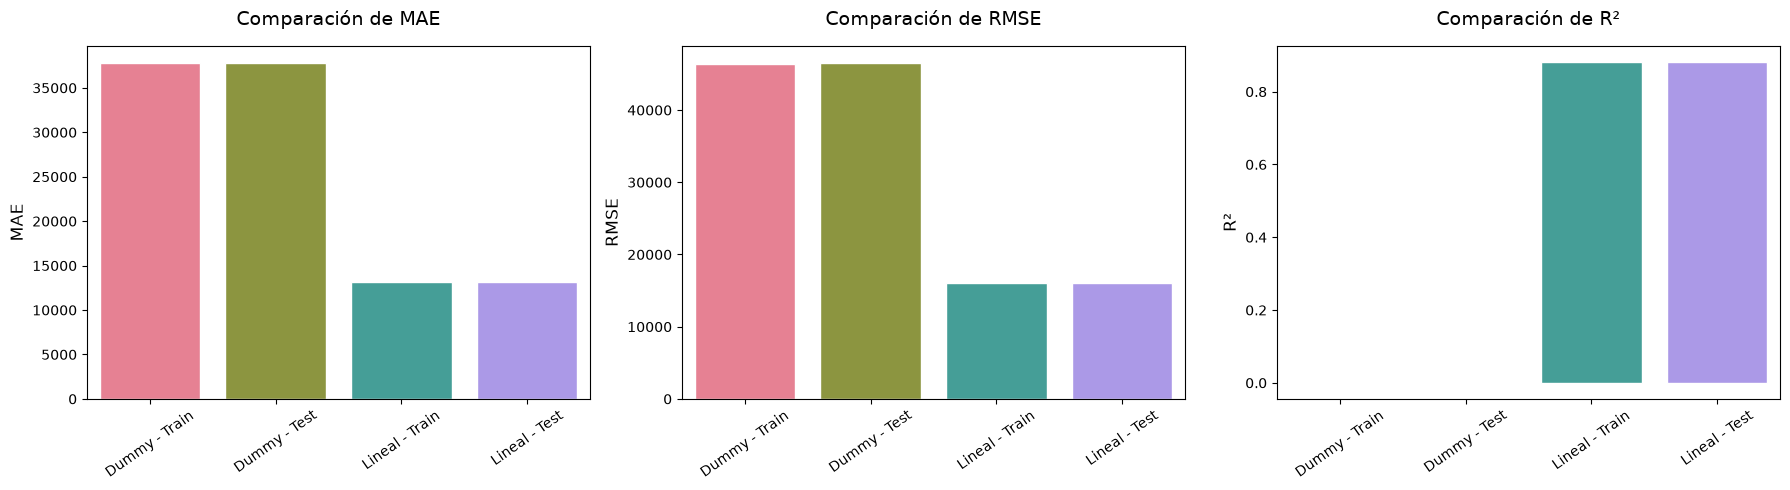

In [278]:

# Organizamos las métricas para graficar
metricas_grafico = ["MAE", "RMSE", "R²"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

paleta = sns.color_palette("husl", len(resultados))

for ax, metrica in zip(axes, metricas_grafico):

    sns.barplot(
        x=resultados.index,
        y=resultados[metrica],
        hue=resultados.index,
        palette=paleta,
        legend=False,
        edgecolor="white",
        linewidth=1,
        ax=ax
    )

    ax.set_title(f"Comparación de {metrica}", fontsize=14, pad=15)
    ax.set_xlabel("")
    ax.set_ylabel(metrica, fontsize=12)
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()


**Interpretación de la comparación entre entrenamiento y test:**

Al comparar los resultados obtenidos, observamos que el modelo de regresión lineal múltiple presenta un desempeño muy similar en los conjuntos de entrenamiento y test.

En entrenamiento, `LinearRegression` obtuvo un **MAE de 13.146,07 USD**, un **RMSE de 15.996,21 USD** y un **R² de 0,881**. Por otro lado, en test presentó un **MAE de 13.185,82 USD**, un **RMSE de 16.001,49 USD** y un **R² de 0,882**.

Las diferencias entre ambos conjuntos son mínimas, lo que indica que el modelo mantiene una capacidad predictiva estable y **no presenta señales evidentes de sobreajuste**.

Asimismo, observamos que `LinearRegression` supera ampliamente al modelo de referencia `DummyRegressor`, cuyos errores son considerablemente mayores y cuyo R² es prácticamente nulo.

Estos resultados sugieren que las variables seleccionadas aportan información relevante para predecir el salario de los desarrolladores y que nuestro modelo presenta una buena capacidad de generalización dentro del dataset analizado.

#### Comparación entre salarios reales y predichos

Utilizamos un gráfico de dispersión para comparar los salarios reales con los valores estimados por nuestro modelo de regresión lineal múltiple.

Agregamos una línea diagonal de referencia que representa una predicción perfecta, es decir, cuando el salario real coincide exactamente con el salario predicho. Mientras más cerca se encuentren los puntos de esta línea, menor será el error de predicción.

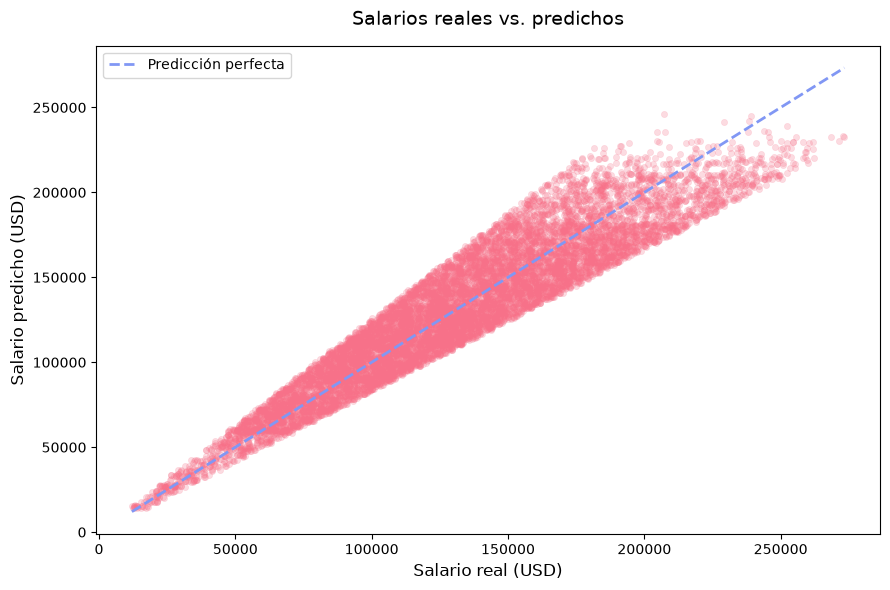

In [279]:

fig, ax = plt.subplots(figsize=(9, 6))

# Colores de la paleta HUSL
paleta = sns.color_palette("husl", 7)

# Gráfico de dispersión
sns.scatterplot(
    x=y_test,
    y=y_test_pred,
    color=paleta[0],
    alpha=0.25,
    s=20,
    edgecolor=None,
    ax=ax
)

# Línea de predicción perfecta
minimo = min(y_test.min(), y_test_pred.min())
maximo = max(y_test.max(), y_test_pred.max())

ax.plot(
    [minimo, maximo],
    [minimo, maximo],
    color=paleta[5],
    linestyle="--",
    linewidth=2,
    label="Predicción perfecta"
)

plt.title("Salarios reales vs. predichos", fontsize=14, pad=15)
plt.xlabel("Salario real (USD)", fontsize=12)
plt.ylabel("Salario predicho (USD)", fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()


**Interpretación del gráfico de salarios reales vs. predichos:**

El gráfico muestra que los salarios predichos por el modelo se encuentran, en general, próximos a los salarios reales, lo que indica un buen nivel de ajuste.

La cercanía de muchos puntos a la línea de predicción perfecta sugiere que el modelo logra estimar adecuadamente el salario en la mayoría de los registros.

No obstante, en los salarios más altos se observa cierta tendencia a la subestimación, ya que varios puntos se ubican por debajo de la línea diagonal.

En términos generales, el gráfico respalda los resultados obtenidos con las métricas de evaluación y confirma que el modelo presenta una buena capacidad predictiva.

#### Análisis de residuos

Analizamos los errores de predicción del modelo mediante un gráfico de residuos.

Este análisis permite observar si los errores se distribuyen alrededor de cero o si presentan patrones que podrían indicar limitaciones del modelo. Idealmente, los residuos deberían distribuirse sin patrones sistemáticos evidentes y sin cambios demasiado pronunciados en su dispersión.

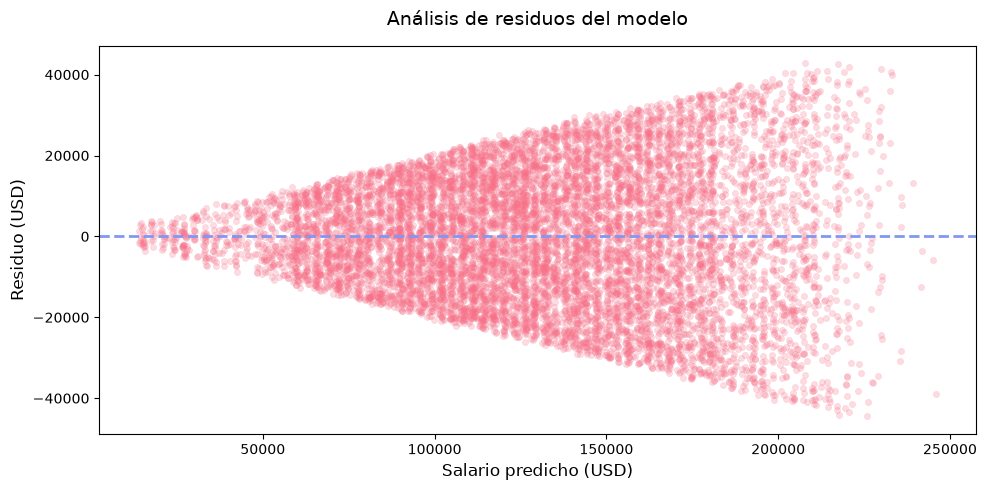

In [280]:

# Calculamos los residuos de test
residuos = y_test - y_test_pred

fig, ax = plt.subplots(figsize=(10, 5))

paleta = sns.color_palette("husl", 7)

sns.scatterplot(
    x=y_test_pred,
    y=residuos,
    color=paleta[0],
    alpha=0.25,
    s=20,
    edgecolor=None,
    ax=ax
)

# Línea de referencia en cero
ax.axhline(
    0,
    color=paleta[5],
    linestyle="--",
    linewidth=2
)

plt.title("Análisis de residuos del modelo", fontsize=14, pad=15)
plt.xlabel("Salario predicho (USD)", fontsize=12)
plt.ylabel("Residuo (USD)", fontsize=12)
plt.tight_layout()
plt.show()


**Interpretación del análisis de residuos:**

Al analizar los residuos del modelo de regresión lineal múltiple, observamos que estos se distribuyen tanto por encima como por debajo de la línea horizontal que representa el error cero.

Sin embargo, la dispersión de los residuos aumenta a medida que crece el salario predicho, formando un patrón similar a un abanico. Este comportamiento sugiere la presencia de **heterocedasticidad**, es decir, que la variabilidad de los errores no es constante.

Esto indica que el modelo presenta errores de menor magnitud al estimar salarios bajos, mientras que las predicciones de salarios más elevados muestran una mayor variabilidad.

Aunque el modelo obtuvo un **R² de 0,882** en test, este análisis evidencia una limitación importante: la precisión de las predicciones no es uniforme para todos los niveles salariales.

Por lo tanto, si bien el modelo presenta un buen desempeño general, podría mejorarse mediante nuevas variables predictoras o transformaciones que permitan reducir la variabilidad de los errores.

#### Comparación de predicciones individuales

Para complementar la evaluación, seleccionamos algunos registros del conjunto de test y comparamos sus salarios reales con las predicciones realizadas por el modelo.

Calculamos la diferencia entre ambos valores para observar ejemplos concretos de los errores de predicción.

In [281]:

# Construimos una tabla de predicciones
comparacion = pd.DataFrame({
    "Salario real": y_test,
    "Salario predicho": y_test_pred,
    "Error": y_test - y_test_pred
}, index=y_test.index)

# Mostramos 10 registros
display(comparacion.head(10).round(2))


,Salario real,Salario predicho,Error
33553,36061,42189.47,-6128.47
9427,150361,153334.28,-2973.28
199,152916,171935.70,-19019.70
12447,99574,86240.21,13333.79
39489,125920,104983.18,20936.82
42724,128161,120255.73,7905.27
10822,83507,92219.97,-8712.97
49498,103503,126490.47,-22987.47
4144,192110,223529.87,-31419.87
36958,125284,131814.54,-6530.54


**Interpretación de las predicciones individuales:**

Al comparar los salarios reales con las predicciones realizadas por el modelo de regresión lineal múltiple, observamos que existen diferencias de distinta magnitud entre los valores.

En algunos casos, las predicciones se aproximan bastante a los salarios reales, mientras que en otros presentan errores más elevados.

Por ejemplo, para un salario real de **36.061 USD**, el modelo predijo **42.189,47 USD**, sobreestimando el valor en 6.128,47 USD. En cambio, para un salario real de **99.574 USD**, estimó **86.240,21 USD**, subestimándolo en 13.333,79 USD.

También encontramos un caso con un salario real de **192.110 USD**, donde la predicción alcanzó los **223.529,87 USD**, generando una sobreestimación de 31.419,87 USD.

Estos ejemplos muestran que el modelo puede presentar errores tanto positivos como negativos, y que algunas predicciones individuales pueden alejarse considerablemente de los valores reales.

Sin embargo, estos diez registros constituyen únicamente una muestra ilustrativa. Para evaluar el desempeño general del modelo debemos considerar las métricas calculadas sobre todo el conjunto de test, donde obtuvimos un **MAE de 13.185,82 USD y un R² de 0,882**.

**Conclusión de la evaluación**

En esta etapa evaluamos el desempeño del modelo de regresión lineal múltiple utilizando los conjuntos de entrenamiento y test, comparándolo con un modelo de referencia (`DummyRegressor`).

Los resultados muestran que **LinearRegression supera ampliamente al modelo de referencia**, obteniendo un **R² de 0,881 en entrenamiento y 0,882 en test**. Esto indica que el modelo logra explicar aproximadamente el 88 % de la variabilidad de los salarios.

Además, obtuvo un **MAE de 13.185,82 USD y un RMSE de 16.001,49 USD en test**, valores considerablemente menores que los obtenidos por DummyRegressor. Las diferencias mínimas entre entrenamiento y test sugieren una buena capacidad de generalización, sin señales evidentes de sobreajuste.

Sin embargo, el análisis de residuos mostró una dispersión creciente a medida que aumenta el salario predicho, lo que sugiere la presencia de **heterocedasticidad**. Esto indica que los errores de predicción presentan una mayor variabilidad en los salarios elevados.

Asimismo, la comparación entre salarios reales y predichos, junto con las predicciones individuales, permitió observar que el modelo puede tanto sobreestimar como subestimar los salarios, presentando errores de distinta magnitud.

En conclusión, **el modelo presenta un buen desempeño general y una capacidad predictiva estable**, aunque existen oportunidades de mejora, especialmente en la precisión de las predicciones correspondientes a salarios más elevados.

### **Interpretación de coeficientes del modelo**

#### Obtención de los coeficientes

Una vez entrenado y evaluado el modelo de regresión lineal múltiple, analizamos los coeficientes calculados por LinearRegression.

Cada coeficiente representa el cambio estimado en el salario asociado a una variación de una variable predictora, manteniendo constantes las demás características del modelo.

Los coeficientes positivos se asocian con un aumento en el salario estimado, mientras que los negativos se relacionan con una disminución.

Este análisis nos permitirá estudiar qué características profesionales presentan una mayor asociación con las predicciones salariales.

In [282]:
# Creamos una tabla con los coeficientes del modelo
coeficientes = pd.DataFrame({
    "Variable": X_train_modelo.columns,
    "Coeficiente": modelo_lineal.coef_
})

# Calculamos el valor absoluto de los coeficientes
coeficientes["Valor absoluto"] = coeficientes["Coeficiente"].abs()

# Ordenamos por magnitud
coeficientes = coeficientes.sort_values(
    by="Valor absoluto",
    ascending=False
)

# Mostramos los primeros 15 coeficientes
display(coeficientes.head(15).round(2))


,Variable,Coeficiente,Valor absoluto
9,pais_USA,39733.46,39733.46
5,pais_India,-35043.09,35043.09
12,educacion_PhD,19455.13,19455.13
17,tamano_empresa_5000+,15597.96,15597.96
8,pais_UK,10021.37,10021.37
11,educacion_Masters,9949.48,9949.48
4,pais_Germany,9639.11,9639.11
2,pais_Canada,9561.88,9561.88
0,experiencia,3015.98,3015.98
7,pais_Singapore,764.18,764.18


**Interpretación de los coeficientes del modelo:**

Al analizar los coeficientes de la regresión lineal múltiple, observamos que las variables relacionadas con el país de residencia presentan algunas de las mayores magnitudes.

La variable pais_USA obtuvo el coeficiente positivo más elevado (+39.733,46 USD), mientras que pais_India presentó el coeficiente negativo de mayor magnitud (−35.043,09 USD).

También destacan el nivel educativo educacion_PhD (+19.455,13 USD) y el tamaño de empresa tamano_empresa_5000+ (+15.597,96 USD), cuyos coeficientes positivos indican salarios estimados más elevados respecto de sus categorías de referencia, manteniendo constantes las demás variables.

Por otra parte, la variable experiencia presentó un coeficiente de +3.015,98 USD, lo que indica que cada año adicional de experiencia profesional se asocia con un incremento estimado de aproximadamente 3.016 USD en el salario.

Estos resultados sugieren que el país de residencia, el nivel educativo, el tamaño de la empresa y la experiencia profesional están asociados con las predicciones salariales del modelo.

Sin embargo, la magnitud de los coeficientes no permite establecer por sí sola cuál es la variable más importante, ya que las características poseen diferentes escalas y algunas variables binarias pueden presentar dependencias entre sí.

##### Visualización de los coeficientes

Utilizamos un gráfico de barras horizontales para representar los coeficientes del modelo con mayor magnitud.

Este gráfico permite observar el signo y el valor de cada coeficiente, diferenciando las variables asociadas con aumentos o disminuciones en el salario estimado.

Los resultados serán interpretados teniendo en cuenta la escala de las variables y las características de la codificación utilizada.

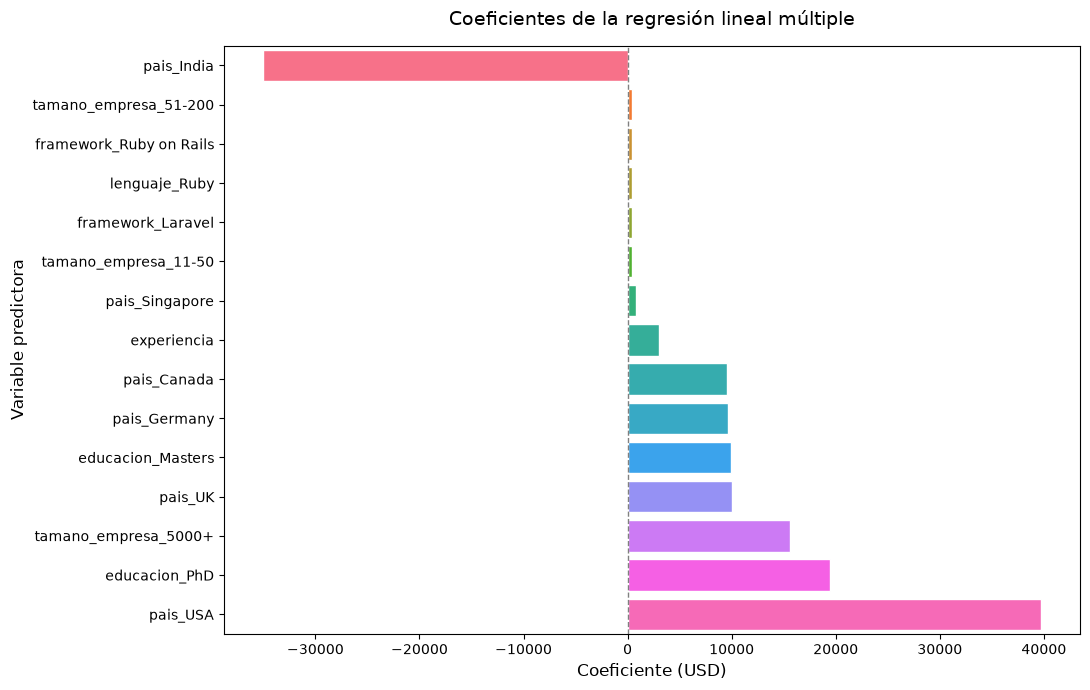

In [283]:
# Seleccionamos los 15 coeficientes de mayor magnitud
top_coeficientes = coeficientes.head(15).sort_values(
    by="Coeficiente"
)

fig, ax = plt.subplots(figsize=(11, 7))

sns.barplot(
    data=top_coeficientes,
    x="Coeficiente",
    y="Variable",
    color="steelblue",
    edgecolor="white",
    linewidth=1,
    ax=ax
)

# Aplicamos la paleta HUSL
paleta_barras = sns.color_palette("husl", len(ax.patches))

for i, barra in enumerate(ax.patches):
    barra.set_facecolor(paleta_barras[i])

# Línea de referencia en cero
ax.axvline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1
)

plt.title("Coeficientes de la regresión lineal múltiple",
          fontsize=14, pad=15)
plt.xlabel("Coeficiente (USD)", fontsize=12)
plt.ylabel("Variable predictora", fontsize=12)

plt.tight_layout()
plt.show()


**Interpretación del gráfico de coeficientes:**

El gráfico permite visualizar los 15 coeficientes de mayor magnitud del modelo de regresión lineal múltiple, diferenciando las asociaciones positivas y negativas con el salario estimado.

Observamos que pais_USA presenta el coeficiente positivo más elevado (+39.733,46 USD), mientras que pais_India muestra el coeficiente negativo de mayor magnitud (−35.043,09 USD).

También destacan las variables relacionadas con el nivel educativo y el tamaño de la empresa, especialmente educacion_PhD (+19.455,13 USD) y tamano_empresa_5000+ (+15.597,96 USD).

Por otra parte, la experiencia profesional presenta un coeficiente positivo de 3.015,98 USD por año, mientras que los lenguajes y frameworks incluidos en el gráfico muestran coeficientes de menor magnitud.

Estos resultados sugieren que el país de residencia, la educación y el tamaño de la empresa presentan asociaciones importantes con el salario estimado. Sin embargo, los coeficientes deben interpretarse considerando las categorías de referencia, las diferentes unidades de medición y las posibles dependencias entre variables.

#### Análisis del coeficiente de experiencia

Analizamos individualmente el coeficiente correspondiente a los años de experiencia profesional.

Este coeficiente permite estimar cuánto cambia el salario predicho por cada año adicional de experiencia, manteniendo constantes las demás variables incluidas en el modelo.

Su interpretación resulta especialmente interesante porque anteriormente encontramos una correlación positiva relativamente fuerte entre la experiencia y el salario.

In [284]:
# Obtenemos el coeficiente de experiencia
coef_experiencia = coeficientes.loc[
    coeficientes["Variable"] == "experiencia",
    "Coeficiente"
].iloc[0]

print(f"Coeficiente de experiencia: {coef_experiencia:,.2f} USD")


Coeficiente de experiencia: 3,015.98 USD


**Interpretación del coeficiente de experiencia:**

El modelo de regresión lineal múltiple obtuvo un coeficiente de +3.015,98 USD para la variable experiencia.

Esto indica que, manteniendo constantes las demás variables predictoras, cada año adicional de experiencia profesional se asocia con un incremento estimado de aproximadamente 3.016 USD en el salario.

Este resultado es coherente con el análisis exploratorio realizado anteriormente, donde encontramos una correlación positiva relativamente fuerte entre la experiencia y el salario (r = 0,77).

Por lo tanto, la experiencia profesional presenta una asociación positiva con el salario estimado y podría ser una variable relevante para la capacidad predictiva del modelo.

Sin embargo, este coeficiente representa una asociación estadística y no demuestra que un año adicional de experiencia provoque necesariamente ese incremento salarial.

#### Importancia de las variables en la predicción

Para complementar la interpretación de los coeficientes, utilizamos la técnica de importancia por permutación (*Permutation Importance*).

Esta técnica permite medir cuánto disminuye el desempeño del modelo cuando se altera aleatoriamente una variable predictora.

De esta manera, podemos identificar qué variables individuales contribuyen más al desempeño predictivo del modelo, sin depender exclusivamente de la magnitud de sus coeficientes.

Los resultados deben interpretarse con precaución cuando existen variables relacionadas entre sí.

In [285]:

# Calculamos la importancia por permutación con datos de test
importancias = permutation_importance(
    modelo_lineal,
    X_test_modelo,
    y_test,
    scoring="r2",
    n_repeats=3,
    random_state=42
)

# Creamos una tabla con los resultados
tabla_importancia = pd.DataFrame({
    "Variable": X_test_modelo.columns,
    "Importancia": importancias.importances_mean
})

# Ordenamos de mayor a menor importancia
tabla_importancia = tabla_importancia.sort_values(
    by="Importancia",
    ascending=False
)

display(tabla_importancia.head(15).round(4))


,Variable,Importancia
0,experiencia,1.1738
9,pais_USA,0.3502
5,pais_India,0.1027
17,tamano_empresa_5000+,0.0293
11,educacion_Masters,0.0184
12,educacion_PhD,0.0162
2,pais_Canada,0.0088
8,pais_UK,0.0087
4,pais_Germany,0.0075
32,framework_Express,0.0001


**Interpretación de la importancia de las variables:**

El análisis de importancia por permutación permitió identificar qué variables contribuyen en mayor medida al desempeño predictivo del modelo de regresión lineal múltiple.

Los resultados muestran que **`experiencia` es la variable de mayor importancia, con un valor de 1,1738**, seguida por `pais_USA` (0,3502) y `pais_India` (0,1027).

Esto indica que modificar aleatoriamente los valores de experiencia provoca la mayor disminución del R², lo que sugiere que el modelo depende considerablemente de esta característica para estimar los salarios.

También observamos que el país de residencia aporta información relevante, especialmente las categorías correspondientes a Estados Unidos e India. Por otra parte, el tamaño de la empresa y el nivel educativo presentan una contribución menor, aunque positiva.

Finalmente, los lenguajes de programación y frameworks muestran valores de importancia muy reducidos, lo que sugiere que su contribución individual al desempeño predictivo del modelo es limitada.

En conjunto, estos resultados indican que **la experiencia profesional es la característica individual más relevante para las predicciones salariales**, seguida por determinadas categorías del país de residencia.

**Conclusión de la interpretación de coeficientes**

El análisis de los coeficientes del modelo permitió identificar las características profesionales que presentan mayores asociaciones con el salario estimado.

La variable `pais_USA` obtuvo el coeficiente positivo de mayor magnitud (**+39.733,46 USD**), mientras que `pais_India` presentó el coeficiente negativo más elevado en valor absoluto (**−35.043,09 USD**).

Por otra parte, la experiencia profesional presentó un coeficiente de **+3.015,98 USD**, indicando que cada año adicional de experiencia se asocia con un incremento estimado de aproximadamente 3.016 USD en el salario, manteniendo constantes las demás variables.

Sin embargo, al complementar este análisis con la importancia por permutación, encontramos que **la experiencia es la variable individual que más contribuye al desempeño predictivo del modelo**, con una importancia de 1,1738.

También identificamos que el país de residencia, el nivel educativo y el tamaño de la empresa aportan información relevante, mientras que los lenguajes de programación y frameworks presentan una contribución individual considerablemente menor.

En conclusión, **la experiencia profesional constituye la variable predictora más relevante del modelo**, mientras que el país de residencia destaca por presentar algunos de los coeficientes de mayor magnitud.

Estos resultados demuestran la importancia de complementar el análisis de coeficientes con técnicas que permitan evaluar la contribución real de las variables al desempeño predictivo.

### **Conclusión del modelo de regresión lineal múltiple**

**1. ¿Cuál fue el desempeño del modelo?**

**Respuesta:** El modelo de regresión lineal múltiple presentó un buen desempeño predictivo, superando ampliamente al modelo de referencia DummyRegressor.

En el conjunto de test, LinearRegression obtuvo un R² de 0,882, lo que significa que logró explicar aproximadamente el 88,2 % de la variabilidad de los salarios. Además, presentó un MAE de 13.185,82 USD y un RMSE de 16.001,49 USD, valores considerablemente menores que los obtenidos por el modelo de referencia.

Estos resultados indican que el modelo logra estimar los salarios con un buen nivel de ajuste, aunque todavía presenta errores individuales de distinta magnitud.

**2. ¿Qué variable fue la más influyente según los coeficientes del modelo?**

**Respuesta:** Al analizar los coeficientes, encontramos que pais_USA presentó el coeficiente positivo de mayor magnitud (+39.733,46 USD), mientras que pais_India obtuvo el coeficiente negativo más elevado en valor absoluto (−35.043,09 USD).

Sin embargo, al complementar este análisis mediante importancia por permutación, identificamos que la experiencia profesional fue la variable con mayor contribución al desempeño predictivo, con una importancia de 1,1738.

Además, su coeficiente fue de +3.015,98 USD, lo que indica que cada año adicional de experiencia se asocia con un incremento estimado de aproximadamente 3.016 USD en el salario, manteniendo constantes las demás características.

Por lo tanto, aunque el país de residencia presentó los coeficientes de mayor magnitud, la experiencia fue la variable individual más relevante para la capacidad predictiva del modelo.

**3. ¿Las variables seleccionadas fueron buenas predictoras? ¿Qué otras sugerimos?**

**Respuesta:** En conjunto, las variables seleccionadas resultaron buenas predictoras del salario, como demuestra el R² de 0,882 obtenido en test.

La experiencia profesional y el país de residencia presentaron las contribuciones predictivas individuales más importantes. También observamos que el nivel educativo y el tamaño de la empresa aportaron información adicional, mientras que los lenguajes de programación y frameworks mostraron una contribución individual considerablemente menor.

Para mejorar el modelo, consideramos que sería interesante incorporar otras características, como la especialización profesional del desarrollador (Frontend, Backend, Full Stack o Data Science), el puesto o nivel de responsabilidad, el tipo de empresa y la modalidad de trabajo.

Estas variables podrían ayudar a explicar diferencias salariales que nuestro modelo actualmente no logra representar.

**4. Comparación de los resultados de entrenamiento y test**

**Respuesta:** Al comparar ambos conjuntos, observamos que el modelo mantiene un desempeño muy similar.

| Métrica | Entrenamiento | Test |
|---|---:|---:|
| MAE | 13.146,07 USD | 13.185,82 USD |
| RMSE | 15.996,21 USD | 16.001,49 USD |
| R² | 0,881 | 0,882 |

Las diferencias son mínimas, lo que sugiere que el modelo presenta una buena capacidad de generalización y no muestra señales evidentes de sobreajuste. Sin embargo, el análisis de residuos permitió identificar una dispersión creciente de los errores a medida que aumenta el salario predicho, lo que sugiere la presencia de heterocedasticidad.

Esto indica que, aunque el modelo presenta un buen desempeño general, sus predicciones tienen una mayor variabilidad de error para los salarios elevados.

### **Conlusion General**

El proyecto permitió desarrollar y evaluar un modelo de regresión lineal múltiple para estimar los salarios de desarrolladores de software a partir de sus características profesionales.

Los resultados demostraron que la experiencia y el país de residencia son factores especialmente relevantes dentro del dataset analizado, mientras que otras variables, como la educación, el tamaño de la empresa y las tecnologías utilizadas, aportaron información complementaria.

El modelo alcanzó un R² de 0,882 en test, superando considerablemente al modelo de referencia y mostrando un comportamiento estable entre entrenamiento y test.

No obstante, identificamos limitaciones relacionadas con la variabilidad de los errores en salarios elevados, lo que plantea oportunidades de mejora mediante la incorporación de nuevas variables y posibles transformaciones.

En conclusión, logramos construir un modelo con buen desempeño predictivo, aplicando las etapas de exploración, preparación, entrenamiento y evaluación de datos, y comprendiendo tanto sus fortalezas como sus limitaciones.